# 03 · Resolution as a function of the triangular-bar size

**Scan setup** (`scripts/scan_bars.sh`, results in `~/runs/scan_bars`):

* full detector, PERPENDICULAR configuration, 270 MeV deuterons, theta uniform in [5°, 17.5°], uniform phi, 500k events per point, same seeds for all points;
* **fixed active area**: 420 mm long bars, 420/b bars per row, 4 rows → 4·420/b SiPM channels; 90 × 90 mm central hole;
* grid: base b ∈ {20, 30, 42, 60, 84} mm × height h ∈ {5, 10, 15, 20, 30} mm (the 2018 prototype is b = 60, h = 20);
* **PHOTOSTAT** smearing calibrated on the test beam (s = 0.180, E_ref = 7 MeV, notebook 02); **CONSTANT** 0.22 for comparison;
* no volume overlaps (Geant4 test on all 25 geometries).

**Metrics** (`sith_reco.py uniform`): in 10 theta intervals the residual θ_reconstructed − θ_generated is fitted with a Gaussian; σ_θ is the mean over the intervals. σ_φ is parametrised as A·cot θ. σ_pos = d_F · σ_θ is the equivalent transverse resolution on the front layer. The efficiency is the fraction of events with a track reconstructed in both layers.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sithplot as sp
sp.setup()
import sith_reco as sr
R = sp.RUNS / "scan_bars"
df = pd.read_csv(R / "summary.csv")
df["model"] = df.model.str.upper()
BASES, HEIGHTS = sorted(df.base_mm.unique()), sorted(df.height_mm.unique())
ph, co = df[df.model == "PHOTOSTAT"], df[df.model == "CONSTANT"]
proto = ph.query("base_mm == 60 and height_mm == 20").iloc[0]
print(f"{len(df)} points; prototype (PHOTOSTAT): σ_θ = {proto.sigma_theta_deg:.4f}°, σ_pos = {proto.sigma_pos_mm:.3f} mm")

50 points; prototype (PHOTOSTAT): σ_θ = 0.0781°, σ_pos = 0.805 mm


## 1. Results table (PHOTOSTAT)

In [2]:
tab = ph.pivot(index="base_mm", columns="height_mm", values="sigma_theta_deg").round(4)
tab.index = [f"b = {b:.0f} mm ({4 * int(420 / b)} channels)" for b in tab.index]
tab.columns = [f"h = {h:.0f} mm" for h in tab.columns]
print("σ_θ [°], PHOTOSTAT model")
tab

σ_θ [°], PHOTOSTAT model


,h = 5 mm,h = 10 mm,h = 15 mm,h = 20 mm,h = 30 mm
b = 20 mm (84 channels),0.0511,0.0388,0.0344,0.0329,0.0341
b = 30 mm (56 channels),0.0744,0.0545,0.0467,0.0425,0.0408
b = 42 mm (40 channels),0.1028,0.0742,0.0623,0.0558,0.0505
b = 60 mm (28 channels),0.1471,0.1060,0.0880,0.0781,0.0687
b = 84 mm (20 channels),0.2008,0.1441,0.1195,0.1056,0.0908


## 2. σ_θ as a function of the base

One line per height. At fixed height the resolution scales roughly linearly with the base: η measures the position over half of the triangle base, so the error in mm grows with b.

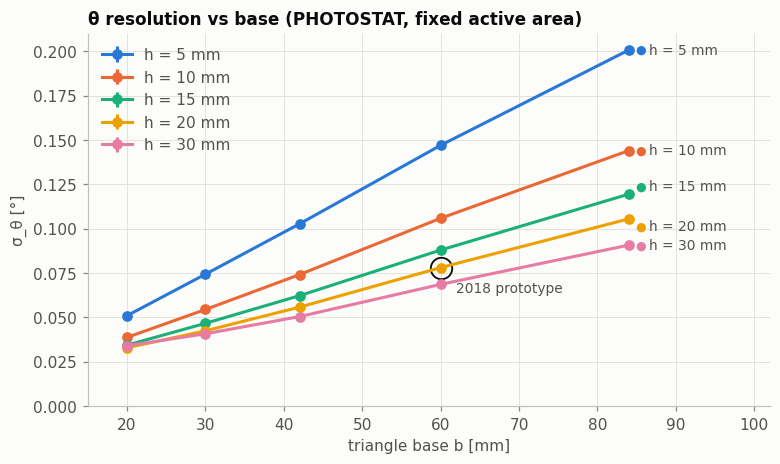

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, h in enumerate(HEIGHTS):
    g = ph[ph.height_mm == h].sort_values("base_mm")
    ax.errorbar(g.base_mm, g.sigma_theta_deg, g.sigma_theta_err, fmt="o-", color=sp.SERIES[i], ms=6, label=f"h = {h:.0f} mm")
    sp.end_label(ax, g.base_mm.iloc[-1], g.sigma_theta_deg.iloc[-1], f"h = {h:.0f} mm", sp.SERIES[i], dy=[0, 0, 5, -5, 0][i])
ax.plot(proto.base_mm, proto.sigma_theta_deg, "o", ms=14, mfc="none", mec=sp.INK, mew=1.2)
ax.annotate("2018 prototype", (proto.base_mm, proto.sigma_theta_deg), xytext=(10, -16), textcoords="offset points",
            ha="left", color=sp.INK2, fontsize=9)
ax.set(xlim=(15, 102), ylim=(0, None), xlabel="triangle base b [mm]", ylabel="σ_θ [°]",
       title="θ resolution vs base (PHOTOSTAT, fixed active area)")
ax.legend(loc="upper left")
plt.show()

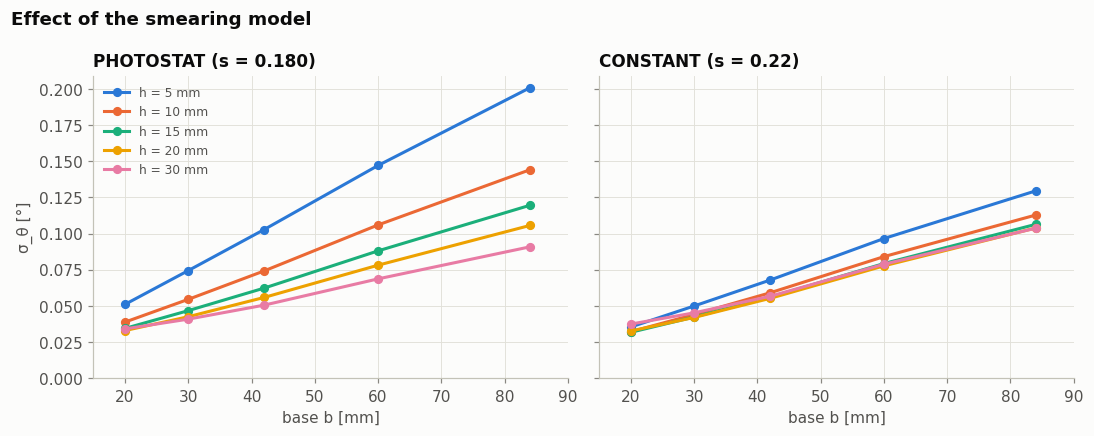

height_mm,5.0,10.0,15.0,20.0,30.0
base_mm,,,,,
20.0,1.441,1.206,1.084,1.008,0.911
30.0,1.490,1.238,1.104,1.012,0.903
42.0,1.515,1.256,1.111,1.012,0.892
60.0,1.523,1.260,1.110,1.006,0.871
84.0,1.550,1.277,1.124,1.017,0.875


In [4]:
# same figure for the two smearing models, same scale
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, d) in zip(axs, (("PHOTOSTAT (s = 0.180)", ph), ("CONSTANT (s = 0.22)", co))):
    for i, h in enumerate(HEIGHTS):
        g = d[d.height_mm == h].sort_values("base_mm")
        ax.plot(g.base_mm, g.sigma_theta_deg, "o-", color=sp.SERIES[i], ms=5, label=f"h = {h:.0f} mm")
    ax.set(title=name, xlabel="base b [mm]", xlim=(15, 90), ylim=(0, None))
axs[0].set_ylabel("σ_θ [°]"); axs[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Effect of the smearing model", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
cmp = ph.merge(co, on=["base_mm", "height_mm"], suffixes=("_ph", "_co"))
cmp["PHOTOSTAT / CONSTANT"] = (cmp.sigma_theta_deg_ph / cmp.sigma_theta_deg_co).round(3)
cmp.pivot(index="base_mm", columns="height_mm", values="PHOTOSTAT / CONSTANT")

With `CONSTANT` the height matters little (the relative energy resolution does not depend on the deposit). With `PHOTOSTAT` low bars lose a lot: at h = 5 mm the deposit is ~4 times smaller than in the prototype and σ_E/E doubles.

## 3. σ_θ as a function of the height: is there an optimal height?

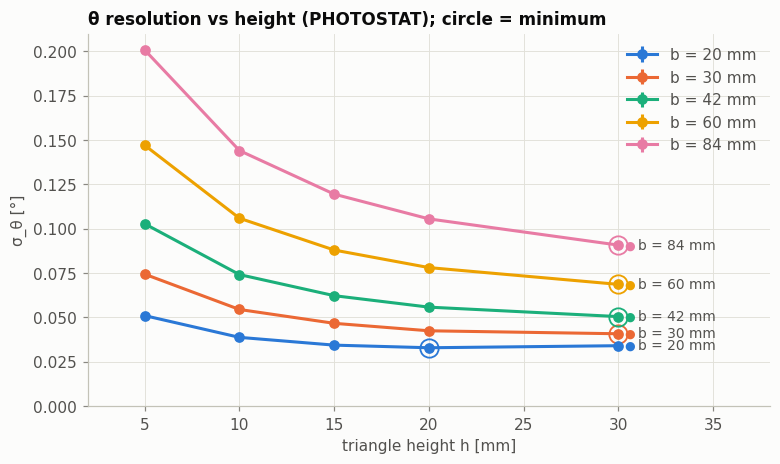

,base_mm,best h [mm],minimum σ_θ [°]
27,20.0,20.0,0.032942
33,30.0,30.0,0.040831
38,42.0,30.0,0.050516
43,60.0,30.0,0.068671
48,84.0,30.0,0.090808


In [5]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, b in enumerate(BASES):
    g = ph[ph.base_mm == b].sort_values("height_mm")
    ax.errorbar(g.height_mm, g.sigma_theta_deg, g.sigma_theta_err, fmt="o-", color=sp.SERIES[i], ms=6, label=f"b = {b:.0f} mm")
    sp.end_label(ax, g.height_mm.iloc[-1], g.sigma_theta_deg.iloc[-1], f"b = {b:.0f} mm", sp.SERIES[i])
    k = g.sigma_theta_deg.idxmin()
    ax.plot(g.loc[k, "height_mm"], g.loc[k, "sigma_theta_deg"], "o", ms=12, mfc="none", mec=sp.SERIES[i], mew=1.2)
ax.set(xlim=(2, 38), ylim=(0, None), xlabel="triangle height h [mm]", ylabel="σ_θ [°]",
       title="θ resolution vs height (PHOTOSTAT); circle = minimum")
ax.legend(loc="upper right")
plt.show()
ph.loc[ph.groupby("base_mm").sigma_theta_deg.idxmin(), ["base_mm", "height_mm", "sigma_theta_deg"]].rename(
    columns={"height_mm": "best h [mm]", "sigma_theta_deg": "minimum σ_θ [°]"})

The trade-off: taller bars deposit more energy (better photostatistics, σ_E/E ∝ 1/√h) but increase multiple scattering and δ-ray fluctuations. Within the grid:

* for **b ≥ 30 mm** the resolution still improves from h = 20 to h = 30 mm (−4% at b = 30, −12% at b = 60): the optimum is above 30 mm, outside the grid;
* only for **b = 20 mm** there is a minimum, at h ≈ 20 mm: with narrow bars multiple scattering weighs more;
* below 10–15 mm the loss is large: at h = 5 mm σ_θ is 1.5 (b = 20) – 1.9 (b = 84) times the value at h = 20 mm.

## 4. Resolution map

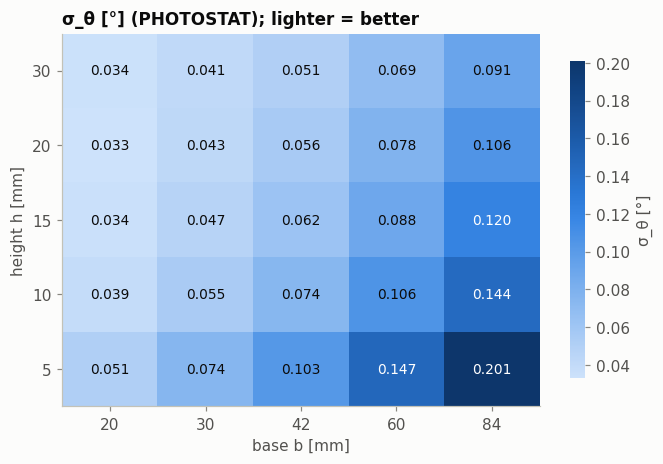

In [6]:
M = ph.pivot(index="height_mm", columns="base_mm", values="sigma_theta_deg")
fig, ax = plt.subplots(figsize=(7, 4.4))
im = ax.imshow(M.values, origin="lower", aspect="auto", cmap="sith_blue")
ax.set_xticks(range(len(M.columns)), [f"{b:.0f}" for b in M.columns])
ax.set_yticks(range(len(M.index)), [f"{h:.0f}" for h in M.index])
ax.grid(False)
vmax = np.nanmax(M.values)
for (i, j), v in np.ndenumerate(M.values):
    ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9, color="#ffffff" if v > 0.55 * vmax else sp.INK)
ax.set(xlabel="base b [mm]", ylabel="height h [mm]", title="σ_θ [°] (PHOTOSTAT); lighter = better")
cb = fig.colorbar(im, ax=ax, shrink=0.85); cb.outline.set_visible(False); cb.set_label("σ_θ [°]", color=sp.INK2)
plt.show()

## 5. The cost: resolution versus number of channels

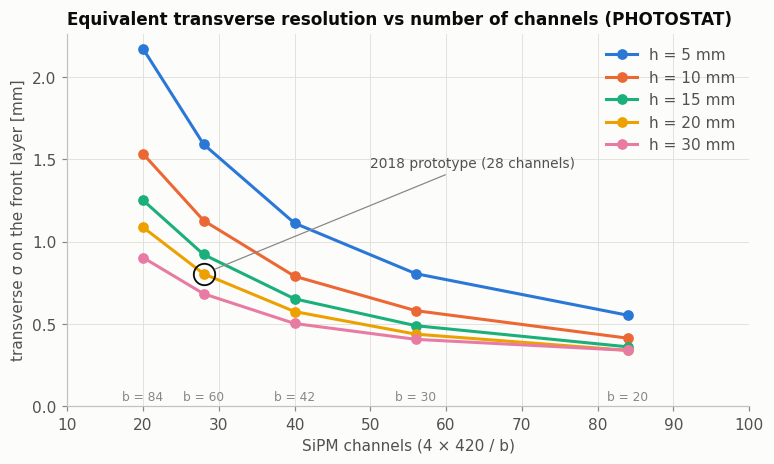

,base_mm,height_mm,channels,sigma_theta_deg,sigma_pos_mm,sigma_phi_A_deg,efficiency,gain vs prototype
27,20.0,20.0,84,0.032942,0.339217,0.032885,0.956636,2.37
28,20.0,30.0,84,0.034097,0.339211,0.032386,0.949252,2.29
26,20.0,15.0,84,0.034422,0.360464,0.035161,0.957024,2.27
25,20.0,10.0,84,0.038800,0.413088,0.040145,0.951838,2.01
33,30.0,30.0,56,0.040831,0.406203,0.040584,0.949014,1.91
32,30.0,20.0,56,0.042506,0.437707,0.044028,0.956980,1.84
31,30.0,15.0,56,0.046713,0.489175,0.048334,0.957710,1.67
38,42.0,30.0,40,0.050516,0.502556,0.051589,0.948976,1.55
29,20.0,5.0,84,0.051054,0.552462,0.053583,0.923910,1.53
30,30.0,10.0,56,0.054516,0.580403,0.056863,0.952282,1.43


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, h in enumerate(HEIGHTS):
    g = ph[ph.height_mm == h].sort_values("channels")
    ax.plot(g.channels, g.sigma_pos_mm, "o-", color=sp.SERIES[i], ms=6, label=f"h = {h:.0f} mm")
ax.plot(proto.channels, proto.sigma_pos_mm, "o", ms=14, mfc="none", mec=sp.INK, mew=1.2)
ax.annotate("2018 prototype (28 channels)", (proto.channels, proto.sigma_pos_mm), xytext=(50, 1.45), textcoords="data",
            color=sp.INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=sp.MUTED, lw=0.8, shrinkB=8))
for b in BASES:
    ax.annotate(f"b = {b:.0f}", (4 * 420 / b, 0), xytext=(0, 4), textcoords="offset points", ha="center", color=sp.MUTED, fontsize=8)
ax.set(xlim=(10, 100), ylim=(0, None), xlabel="SiPM channels (4 × 420 / b)", ylabel="transverse σ on the front layer [mm]",
       title="Equivalent transverse resolution vs number of channels (PHOTOSTAT)")
ax.legend(loc="upper right")
plt.show()
best = ph.copy()
best["gain vs prototype"] = (proto.sigma_theta_deg / best.sigma_theta_deg).round(2)
best.sort_values("sigma_theta_deg")[["base_mm", "height_mm", "channels", "sigma_theta_deg", "sigma_pos_mm",
                                     "sigma_phi_A_deg", "efficiency", "gain vs prototype"]].head(10)

## 6. Phi resolution and efficiency

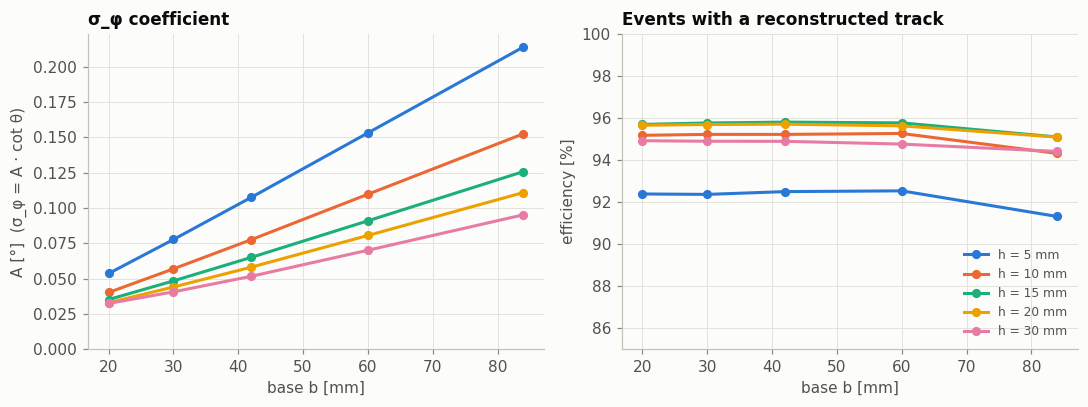

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for i, h in enumerate(HEIGHTS):
    g = ph[ph.height_mm == h].sort_values("base_mm")
    axs[0].plot(g.base_mm, g.sigma_phi_A_deg, "o-", color=sp.SERIES[i], ms=5, label=f"h = {h:.0f} mm")
    axs[1].plot(g.base_mm, 100 * g.efficiency, "o-", color=sp.SERIES[i], ms=5, label=f"h = {h:.0f} mm")
axs[0].set(xlabel="base b [mm]", ylabel="A [°]  (σ_φ = A · cot θ)", title="σ_φ coefficient", ylim=(0, None))
axs[1].set(xlabel="base b [mm]", ylabel="efficiency [%]", title="Events with a reconstructed track", ylim=(85, 100))
axs[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

The efficiency (~95%) is limited mostly by the corners of the central hole at low theta (the same for all geometries) and drops by a few points for the thinnest bars, where more deposits near the apexes fall below the 35 keV threshold.

## 7. Residual distributions for three geometries

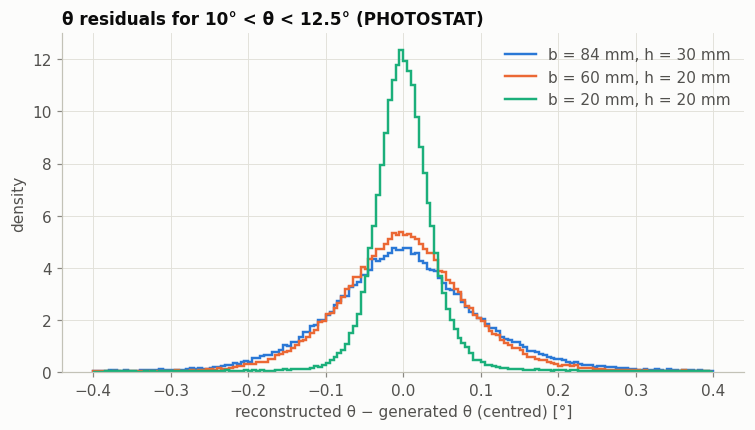

In [9]:
def residuals(b, h):
    d = R / "photostat" / f"b{b}_h{h}"
    geom = sr.Geometry.from_config(d / "config_last.cfg")
    F, B, gen = sr.load(sr.run_files(str(d / "output" / "*MeV_t*-{run}.root"), 0), geom)
    rec = sr.reconstruct(F, B, geom)
    tg = np.degrees(gen["theta_lab"])
    m = (tg > 10) & (tg < 12.5)
    return (rec["theta"] - tg)[m]

fig, ax = plt.subplots(figsize=(8, 4))
for i, (b, h) in enumerate(((84, 30), (60, 20), (20, 20))):
    r = residuals(b, h)
    r = r[np.isfinite(r)]
    sp.hist_line(ax, r - np.median(r), 160, (-0.4, 0.4), sp.SERIES[i], label=f"b = {b} mm, h = {h} mm", density=True)
ax.set(xlabel="reconstructed θ − generated θ (centred) [°]", ylabel="density",
       title="θ residuals for 10° < θ < 12.5° (PHOTOSTAT)")
ax.legend(loc="upper right")
plt.show()

## 8. Conclusions and limitations

* At fixed active area the angular resolution is dominated by the **base**: from 60 to 30 mm (h = 20) σ_θ goes from 0.078° to 0.043° (×1.8), at the price of doubling the channels (28 → 56). The dependence is roughly linear with a constant term (multiple scattering, beam size).
* The **height** matters through photostatistics: with respect to h = 20 mm, 10 mm bars lose a factor 1.2–1.4 and 5 mm bars 1.5–1.9; from 20 to 30 mm the resolution still improves by 4–14% for b ≥ 30 mm, while for b = 20 mm the optimum is at ~20 mm.
* Best compromises in the grid: **b = 30, h = 30** (0.041°, ×1.9 with respect to the prototype, 56 channels); **b = 42, h = 30** (0.051°, ×1.55, 40 channels); **b = 20, h = 20** (0.033°, ×2.4, 84 channels).
* To find how far it pays to make the bars taller, the grid should be extended to h = 40–50 mm for b ≥ 30 mm, taking into account the material in front of the LYSO (point 4 below).

**Limitations to keep in mind before drawing design conclusions:**

1. Same light yield per MeV for all geometries: bars with a smaller cross-section would be better covered by the 6×6 mm² SiPM and would collect more light → the scan is *conservative* for small bars. Attenuation along the bar is not simulated.
2. The smearing calibration uses a single point (prototype geometry, 2018 test beam).
3. The reconstruction uses the nominal pitch b instead of b + 2·(aluminium thickness): 0.1–0.4% bias in theta (absorbed by the fit, it does not affect σ).
4. Only 270 MeV deuterons without target: no background from inelastic scattering. Taller bars mean more plastic in front of the calorimeter (energy loss, nuclear interactions, worse LYSO energy resolution): this cost is not in the metric and limits the useful height.
5. σ_θ here comes from the residuals with uniform theta; for the prototype the fixed-theta scan gives 0.079° (mean of the fits) against 0.078° with this method.